# Modelo V3 — seguimiento completo con `p1_label..p12_label`

Esta versión utiliza las etiquetas semánticas de cada separación (`BEAM_TOP_FLANGE`, `BEAM_WEB_CENTRAL`, `HAUNCH_FLANGE`, `UNUSED`, etc.) que ya contiene el nuevo CSV.

A diferencia de V2, no es necesario inferir la semántica de `p1..p12` mediante reglas geométricas. La red predice conjuntamente:

- `DrawingCode`, `Bolt` y `SlipCritical`.
- `g, Bp, Lp, tp, e, d`.
- La etiqueta de cada posición `p1_label..p12_label`.
- El valor de cada `p1..p12`, aplicando máscara cuando su etiqueta es `UNUSED`.
- Los rigidizadores `tws, ts, tbs, tst`.

El notebook no modifica V2. Cambia `CSV_PATH` para apuntar al archivo completo en tu ordenador.

In [ ]:
from pathlib import Path
import sys, json, pickle
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

MODEL_DIR = Path.cwd() / "data"  # ejecutar el notebook desde V3/model
if str(MODEL_DIR) not in sys.path: sys.path.insert(0, str(MODEL_DIR))
from config import *
from dataset import Preprocessor, ConnectionDataset
from model import ConnectionDesignNet
from losses import ConnectionDesignLoss
from training import fit, predict
from postprocess import decode
from evaluation import evaluate

SEED=42
np.random.seed(SEED); torch.manual_seed(SEED)
CSV_PATH = MODEL_DIR / 'data_pi_tag.csv'  # cambia esta ruta si el CSV está en otra carpeta
CSV_SEPARATOR = ';'
CSV_DECIMAL = '.'
print('PyTorch:',torch.__version__,'| CUDA:',torch.cuda.is_available())

In [ ]:
pd.set_option('display.max_columns', None)  # Muestra todas las columnas
pd.set_option('display.max_rows', None)     # Muestra todas las filas
pd.set_option('display.width', None)        # Ajusta el ancho para no cortar
pd.set_option('display.max_colwidth', None) # Muestra el contenido completo de cada celda

## 1. Carga, esquema y calidad de datos

In [ ]:
df = pd.read_csv(MODEL_DIR / "test_input_25.csv", sep=";", decimal=CSV_DECIMAL)
df.columns = df.columns.str.strip()
print('Dimensiones:',df.shape)
display(df.head())
print('Columnas:',df.columns.tolist())

Dimensiones: (4722, 69)


,Capacity_Moment,Capacity_Shear,Capacity_Axial,g,tws,Bp,Lp,tp,e,d,p1,p2,p3,p4,p5,p6,p7,p8,p9,p10,p11,p12,p1_label,p2_label,p3_label,p4_label,p5_label,p6_label,p7_label,p8_label,p9_label,p10_label,p11_label,p12_label,ts,tbs,tst,Hole,BEAM,COLUMN,DrawingCode,Bolt,SlipCritical,grado_acero,clase_tornillo,Source,standard,BEAM_type,BEAM_d_mm,BEAM_bf_mm,BEAM_tw_mm,BEAM_tf_mm,BEAM_r1_mm,BEAM_wely_mm,BEAM_w_kgm,COLUMN_type,COLUMN_d_mm,COLUMN_bf_mm,COLUMN_tw_mm,COLUMN_tf_mm,COLUMN_r1_mm,COLUMN_wely_mm,COLUMN_w_kgm,fy_acero_mpa,fu_acero_mpa,fy_tornillo_mpa,fu_tornillo_mpa,fv_tornillo_mpa,tiene_cantonera
0,150.580350,226.845000,171.8910,120,0,180,480,20,40,50.0,110.0,90.0,90.0,110.0,0.0,0,0,0,0,0,0,0,BEAM_TOP_FLANGE,BEAM_WEB_EXTREME,BEAM_WEB_EXTREME,BEAM_BOTTOM_FLANGE,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,10,0,10,27,IPE300,HEB240,MLE,M24,YES,S355JR,A325M,European,AISC-360-05/10,IPE,300,150,7.1,10.7,15.0,557.0,42.2,HE,240,240,10.0,17.0,21.0,938.3,83.199997,355,490,660,830,372,False
1,49.141125,105.106617,0.0000,140,0,200,330,15,40,40.0,90.0,70.0,90.0,0.0,0.0,0,0,0,0,0,0,0,BEAM_TOP_FLANGE,BEAM_WEB_CENTRAL,BEAM_BOTTOM_FLANGE,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,10,0,10,22,HEA180,HEA300,MLE,M20,NO,S275JR,8.8,European,EN 1993-1-8,HE,171,180,6.0,9.5,15.0,293.6,35.5,HE,290,300,8.5,14.0,27.0,1260.0,88.300000,275,430,640,800,480,False
2,461.613600,434.520000,546.0255,145,0,300,830,30,50,60.0,145.0,85.0,250.0,85.0,180.0,0,0,0,0,0,0,0,BEAM_TOP_FLANGE,BEAM_WEB_CENTRAL,BEAM_BOTTOM_FLANGE,HAUNCH_WEB_CENTRAL,HAUNCH_FLANGE,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,10,10,10,33,HEB340,HEA400,MHE,M30,YES,S355JR,A325M,European,AISC-360-05/10,HE,340,300,12.0,21.5,27.0,2156.0,134.0,HE,390,300,11.0,19.0,27.0,2311.0,125.000000,355,490,660,830,372,True
3,101.175000,0.000000,0.0000,120,0,200,380,20,40,40.0,100.0,100.0,100.0,0.0,0.0,0,0,0,0,0,0,0,BEAM_TOP_FLANGE,BEAM_WEB_CENTRAL,BEAM_BOTTOM_FLANGE,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,10,0,0,26,IPE220,HEB260,MLE,M24,NO,S355JR,10.9,European,EN 1993-1-8 - SP RK EN 1993-1-8:2005/2011,IPE,220,110,5.9,9.2,12.0,252.0,26.2,HE,260,260,10.0,17.5,24.0,1148.0,93.000000,355,490,900,1000,500,False
4,695.775150,456.885000,508.0050,150,0,300,905,25,45,55.0,130.0,75.0,165.0,210.0,75.0,160,0,0,0,0,0,0,BEAM_TOP_FLANGE,BEAM_WEB_EXTREME,BEAM_WEB_EXTREME,BEAM_BOTTOM_FLANGE,HAUNCH_WEB_CENTRAL,HAUNCH_FLANGE,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,UNUSED,10,10,10,30,HEA400,HEB800,MHE,M27,YES,S355JR,A325M,European,AISC-360-05/10,HE,390,300,11.0,19.0,27.0,2311.0,125.0,HE,800,300,17.5,33.0,30.0,8980.0,262.000000,355,490,660,830,372,True


Columnas: ['Capacity_Moment', 'Capacity_Shear', 'Capacity_Axial', 'g', 'tws', 'Bp', 'Lp', 'tp', 'e', 'd', 'p1', 'p2', 'p3', 'p4', 'p5', 'p6', 'p7', 'p8', 'p9', 'p10', 'p11', 'p12', 'p1_label', 'p2_label', 'p3_label', 'p4_label', 'p5_label', 'p6_label', 'p7_label', 'p8_label', 'p9_label', 'p10_label', 'p11_label', 'p12_label', 'ts', 'tbs', 'tst', 'Hole', 'BEAM', 'COLUMN', 'DrawingCode', 'Bolt', 'SlipCritical', 'grado_acero', 'clase_tornillo', 'Source', 'standard', 'BEAM_type', 'BEAM_d_mm', 'BEAM_bf_mm', 'BEAM_tw_mm', 'BEAM_tf_mm', 'BEAM_r1_mm', 'BEAM_wely_mm', 'BEAM_w_kgm', 'COLUMN_type', 'COLUMN_d_mm', 'COLUMN_bf_mm', 'COLUMN_tw_mm', 'COLUMN_tf_mm', 'COLUMN_r1_mm', 'COLUMN_wely_mm', 'COLUMN_w_kgm', 'fy_acero_mpa', 'fu_acero_mpa', 'fy_tornillo_mpa', 'fu_tornillo_mpa', 'fv_tornillo_mpa', 'tiene_cantonera']


In [ ]:
missing_cols=sorted(set(REQUIRED_COLUMNS)-set(df.columns))
assert not missing_cols, f'Faltan columnas obligatorias: {missing_cols}'
print('Columnas obligatorias: OK')
quality=pd.DataFrame({'dtype':df.dtypes.astype(str),'nulos':df.isna().sum(),'pct_nulos':100*df.isna().mean(),'unicos':df.nunique(dropna=False)})
display(quality.sort_values(['pct_nulos','unicos'],ascending=[False,True]))
print('Filas duplicadas completas:',df.duplicated().sum())

Columnas obligatorias: OK


,dtype,nulos,pct_nulos,unicos
p1_label,str,0,0.0,1
p11,int64,0,0.0,2
p12,int64,0,0.0,2
p11_label,str,0,0.0,2
p12_label,str,0,0.0,2
SlipCritical,str,0,0.0,2
grado_acero,str,0,0.0,2
Source,str,0,0.0,2
fy_acero_mpa,int64,0,0.0,2
fu_acero_mpa,int64,0,0.0,2


Filas duplicadas completas: 2


In [ ]:
# Normalización mínima y validaciones. No se eliminan duplicados automáticamente.
for c in CATEGORICAL_FEATURES + CLASSIFICATION_TARGETS + P_LABEL_COLUMNS:
    df[c]=df[c].fillna('UNUSED' if c in P_LABEL_COLUMNS else 'UNKNOWN').astype(str).str.strip()
for c in NUMERIC_FEATURES + REGRESSION_ALWAYS + P_COLUMNS + STIFFENER_COLUMNS:
    df[c]=pd.to_numeric(df[c],errors='coerce')
assert not df[NUMERIC_FEATURES+REGRESSION_ALWAYS].isna().any().any(), 'Hay NaN en entradas/targets continuos obligatorios'
# Una posición UNUSED debe tener valor 0; se informa y se corrige en la copia de trabajo.
for p,l in zip(P_COLUMNS,P_LABEL_COLUMNS):
    bad=(df[l]=='UNUSED') & (df[p].fillna(0)!=0)
    if bad.any(): print(f'Aviso: {bad.sum()} filas con {l}=UNUSED y {p}!=0; se fija a 0')
    df.loc[df[l]=='UNUSED',p]=0
df[P_COLUMNS+STIFFENER_COLUMNS]=df[P_COLUMNS+STIFFENER_COLUMNS].fillna(0)
print('Validación básica completada')

Validación básica completada


## 2. Exploración de objetivos

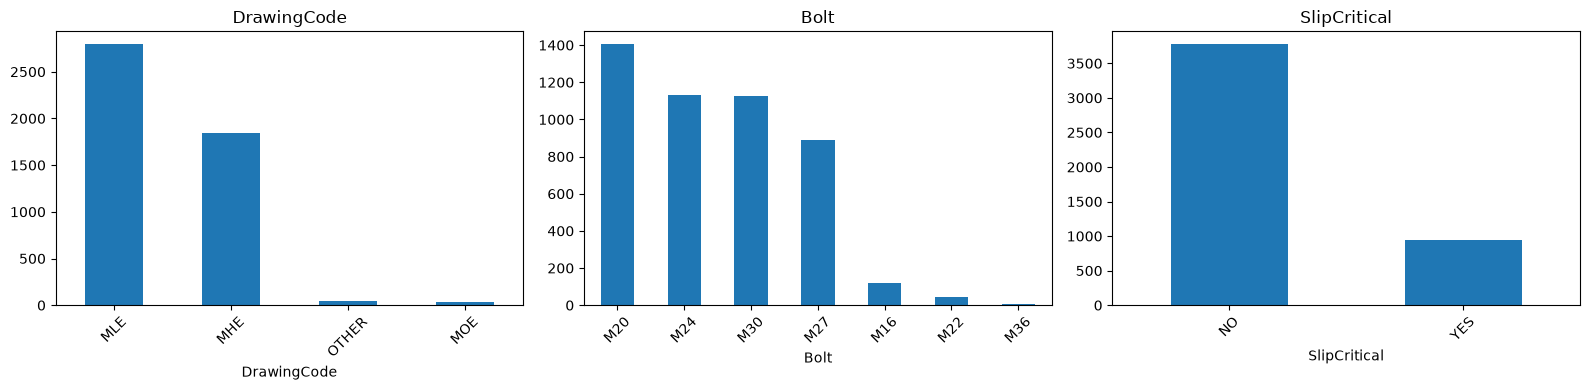

Etiquetas p globales:


,N
UNUSED,35046
BEAM_TOP_FLANGE,4722
BEAM_BOTTOM_FLANGE,4720
BEAM_WEB_EXTREME,3858
BEAM_WEB_CENTRAL,3007
HAUNCH_FLANGE,2536
HAUNCH_WEB_CENTRAL,1565
HAUNCH_WEB_EXTREME,992
BEAM_WEB_ADJ_CENTER,184
HAUNCH_WEB_ADJ_CENTER,26


In [ ]:
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,c in zip(axes,['DrawingCode','Bolt','SlipCritical']):
    df[c].value_counts().plot.bar(ax=ax,title=c); ax.tick_params(axis='x',rotation=45)
plt.tight_layout();plt.show()
print('Etiquetas p globales:')
display(pd.Series(df[P_LABEL_COLUMNS].to_numpy().ravel()).value_counts().to_frame('N'))

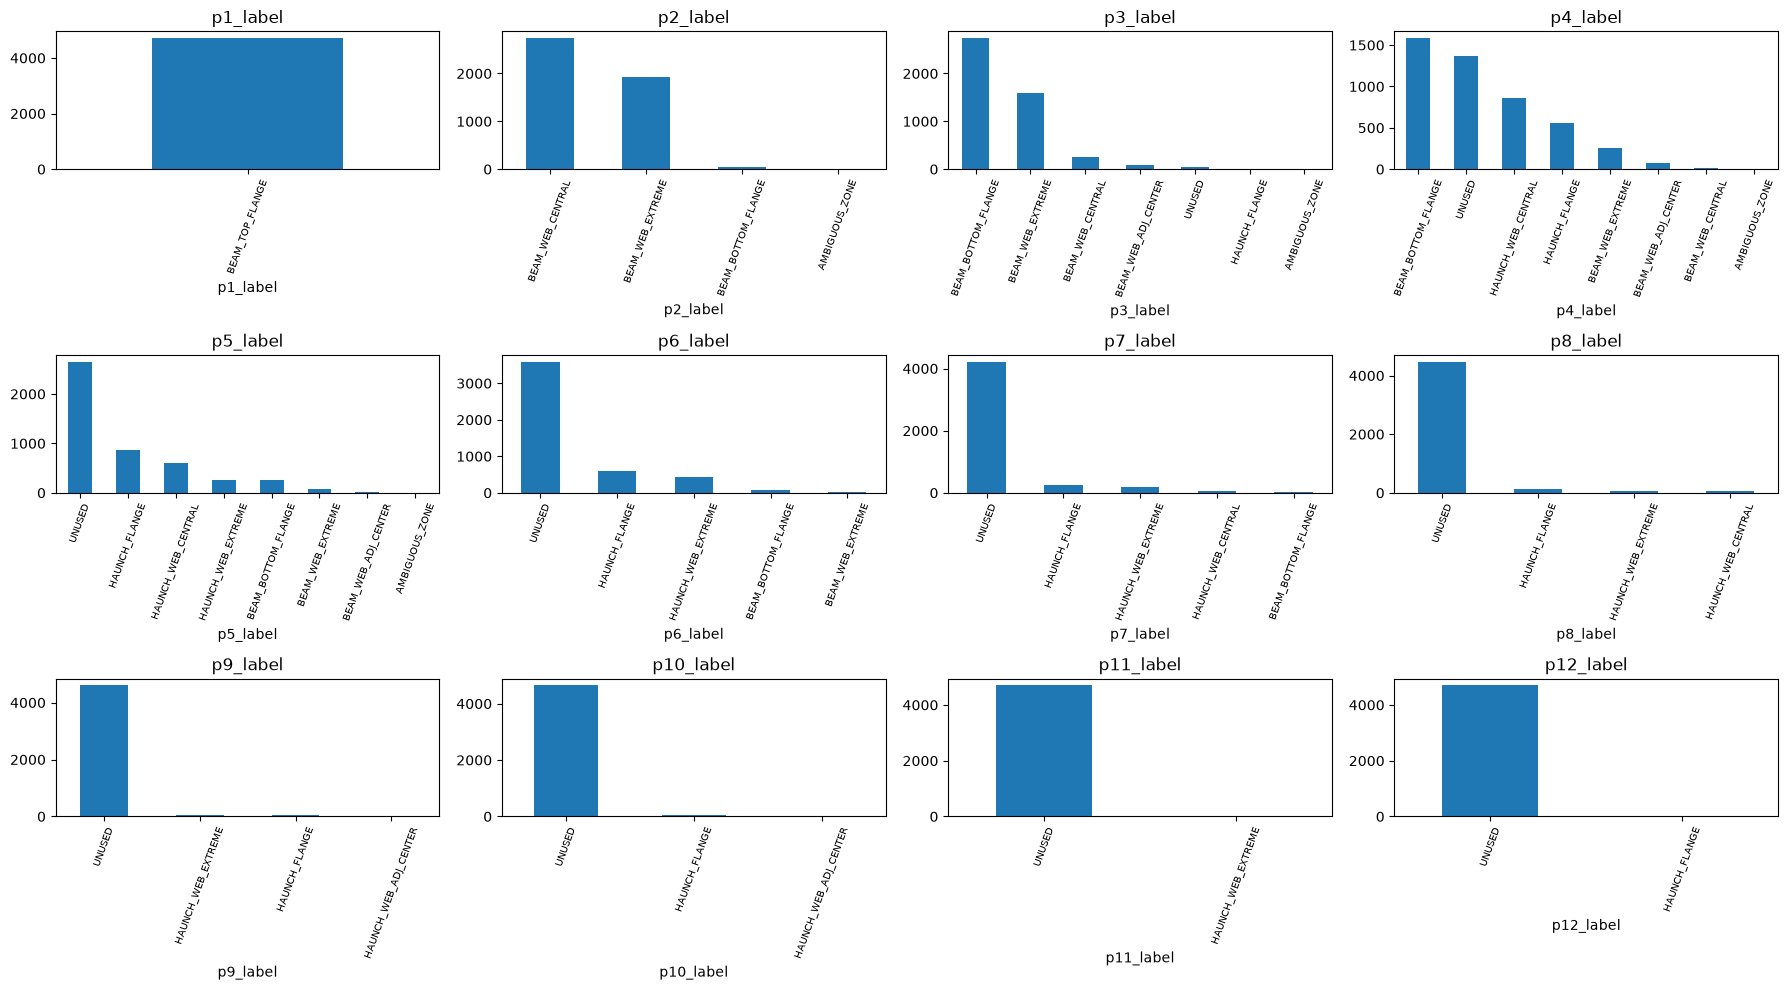

In [ ]:
fig,axes=plt.subplots(3,4,figsize=(18,10))
for ax,c in zip(axes.flat,P_LABEL_COLUMNS):
    df[c].value_counts().plot.bar(ax=ax,title=c);ax.tick_params(axis='x',rotation=70,labelsize=7)
plt.tight_layout()
plt.show()

In [ ]:
display(df[REGRESSION_ALWAYS+P_COLUMNS+STIFFENER_COLUMNS].describe().T)
print('Porcentaje activo:')
display(pd.Series({c:100*(df[c].fillna(0)>0).mean() for c in P_COLUMNS+STIFFENER_COLUMNS},name='% activo'))

,count,mean,std,min,25%,50%,75%,max
g,4722.0,128.846887,15.687968,80.0,120.0,140.0,140.000000,165.0
Bp,4722.0,249.501271,52.061913,140.0,200.0,240.0,300.000000,390.0
Lp,4722.0,645.600593,271.282593,250.0,450.0,590.0,765.000000,1820.0
tp,4722.0,22.294155,5.543122,12.0,20.0,20.0,25.000000,60.0
e,4722.0,45.367429,5.708396,35.0,40.0,45.0,50.000000,65.0
d,4722.0,49.216130,8.283854,31.0,40.0,50.0,56.066061,70.0
p1,4722.0,116.315354,23.023368,73.5,100.0,115.0,136.125000,170.0
p2,4722.0,102.247310,35.912874,45.0,75.0,95.0,125.000000,300.8
p3,4722.0,131.871262,46.074999,0.0,100.0,125.0,150.000000,295.0
p4,4722.0,90.730176,68.083065,0.0,0.0,105.0,140.000000,270.0


Porcentaje activo:


p1     100.000000
p2     100.000000
p3      99.131724
p4      71.113935
p5      43.752647
p6      23.867006
p7      10.504024
p8       5.146125
p9       2.329521
p10      1.418890
p11      0.275307
p12      0.275307
tws      2.435409
ts      95.955104
tbs     54.913172
tst     51.927150
Name: % activo, dtype: float64

## 3. Separación train / validación / test
Se estratifica por `DrawingCode` cuando todas las clases tienen suficientes muestras. El test queda aislado hasta la evaluación final.

In [ ]:
def safe_stratify(frame,col='DrawingCode'):
    vc=frame[col].value_counts(); return frame[col] if len(vc)>1 and vc.min()>=2 else None
train_val,test_df=train_test_split(df,test_size=.20,random_state=SEED,stratify=safe_stratify(df))
train_df,val_df=train_test_split(train_val,test_size=.1875,random_state=SEED,stratify=safe_stratify(train_val)) # 65/15/20
for name,x in [('train',train_df),('val',val_df),('test',test_df)]:
    print(name,len(x),x['DrawingCode'].value_counts(normalize=True).round(3).to_dict())
train_df=train_df.reset_index(drop=True);val_df=val_df.reset_index(drop=True);test_df=test_df.reset_index(drop=True)

train 3068 {'MLE': 0.591, 'MHE': 0.391, 'OTHER': 0.01, 'MOE': 0.007}
val 709 {'MLE': 0.592, 'MHE': 0.391, 'OTHER': 0.01, 'MOE': 0.007}
test 945 {'MLE': 0.592, 'MHE': 0.39, 'OTHER': 0.011, 'MOE': 0.007}


## 4. Preprocesador y DataLoaders
Todos los encoders y escaladores se ajustan **solo con train**. Las categorías desconocidas de entrada se aceptan mediante un índice reservado.

In [ ]:
pre=Preprocessor().fit(train_df)
print('Cardinalidades:',pre.cat_cardinalities)
print('DrawingCode:',pre.drawing_encoder.classes_)
print('Etiquetas p:',pre.p_label_encoder.classes_)
train_ds=ConnectionDataset(train_df,pre);val_ds=ConnectionDataset(val_df,pre);test_ds=ConnectionDataset(test_df,pre)
train_loader=DataLoader(train_ds,batch_size=64,shuffle=True,drop_last=len(train_ds)>=64)
val_loader=DataLoader(val_ds,batch_size=256);test_loader=DataLoader(test_ds,batch_size=256)
batch=next(iter(train_loader))
for k,v in batch.items():print(f'{k:18} {tuple(v.shape)} {v.dtype}')

Cardinalidades: [4, 5, 3, 4, 3, 5]
DrawingCode: ['MHE' 'MLE' 'MOE' 'OTHER']
Etiquetas p: ['AMBIGUOUS_ZONE' 'BEAM_BOTTOM_FLANGE' 'BEAM_TOP_FLANGE'
 'BEAM_WEB_ADJ_CENTER' 'BEAM_WEB_CENTRAL' 'BEAM_WEB_EXTREME'
 'HAUNCH_FLANGE' 'HAUNCH_WEB_ADJ_CENTER' 'HAUNCH_WEB_CENTRAL'
 'HAUNCH_WEB_EXTREME' 'UNUSED']
x_cat              (64, 6) torch.int64
x_num              (64, 22) torch.float32
drawing_idx        (64,) torch.int64
bolt_idx           (64,) torch.int64
slip               (64,) torch.float32
reg                (64, 6) torch.float32
p_label_idx        (64, 12) torch.int64
masked_value       (64, 16) torch.float32
masked_mask        (64, 16) torch.float32


## 5. Construcción del modelo

In [ ]:
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model=ConnectionDesignNet(pre.cat_cardinalities,len(NUMERIC_FEATURES),pre.n_drawing_codes,pre.n_p_labels).to(device)
print('Device:',device,'| Parámetros:',f'{sum(x.numel() for x in model.parameters()):,}')
model

Device: cpu | Parámetros: 264,224


ConnectionDesignNet(
  (emb): ModuleList(
    (0): Embedding(4, 2)
    (1): Embedding(5, 3)
    (2): Embedding(3, 2)
    (3): Embedding(4, 2)
    (4): Embedding(3, 2)
    (5): Embedding(5, 3)
  )
  (input): Sequential(
    (0): Linear(in_features=36, out_features=192, bias=True)
    (1): BatchNorm1d(192, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
  )
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (net): Sequential(
        (0): Linear(in_features=192, out_features=192, bias=True)
        (1): BatchNorm1d(192, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): Dropout(p=0.1, inplace=False)
        (4): Linear(in_features=192, out_features=192, bias=True)
        (5): BatchNorm1d(192, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
  )
  (drawing): Linear(in_features=192, out_features=4, bias=True)
  (bolt): Linear(in_features=192, out_features=7, bias=True)
  (slip): Lin

In [ ]:
# Comprobación de dimensiones antes de entrenar
with torch.no_grad():
    out=model(batch['x_cat'].to(device),batch['x_num'].to(device))
for k,v in out.items():print(f'{k:20} {tuple(v.shape)}')

drawing_logits       (64, 4)
bolt_logits          (64, 7)
slip_logit           (64,)
reg                  (64, 6)
p_label_logits       (64, 12, 11)
masked_value         (64, 16)


## 6. Entrenamiento

In [ ]:
EPOCHS=150
LEARNING_RATE=0.005
criterion=ConnectionDesignLoss()
history=fit(model,train_loader,val_loader,criterion,device,epochs=EPOCHS,lr=LEARNING_RATE)
print('Mejor época:',history['best_epoch'])

001/150 train=3.1313 val=2.0923
015/150 train=0.9230 val=0.9139
030/150 train=0.7061 val=0.7727
045/150 train=0.5338 val=0.7486
060/150 train=0.4446 val=0.6212
075/150 train=0.3904 val=0.5321
090/150 train=0.3700 val=0.6079
105/150 train=0.3892 val=0.5704
120/150 train=0.2903 val=0.5496
135/150 train=0.2995 val=0.5721
150/150 train=0.2913 val=0.6204
Mejor época: 93


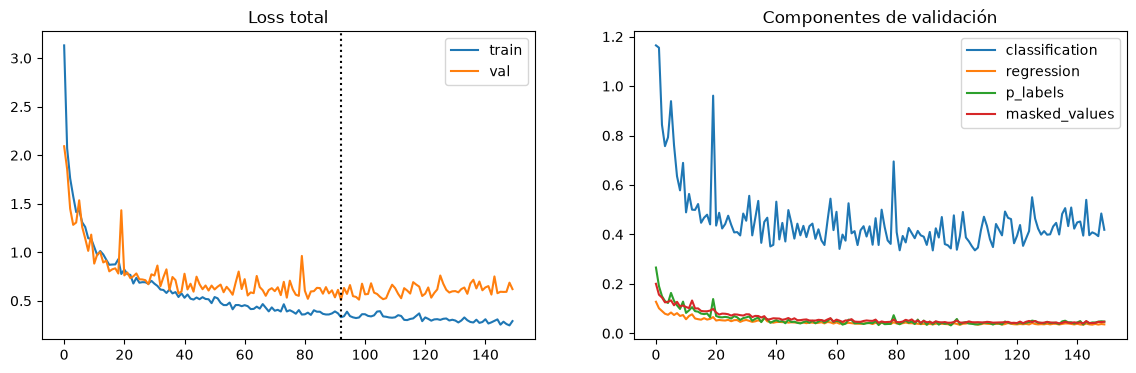

In [ ]:
fig,axes=plt.subplots(1,2,figsize=(14,4))
axes[0].plot(history['train_loss'],label='train');axes[0].plot(history['val_loss'],label='val');axes[0].axvline(history['best_epoch']-1,ls=':',c='k');axes[0].legend();axes[0].set_title('Loss total')
for key in history['val_parts'][0]: axes[1].plot([x[key] for x in history['val_parts']],label=key)
axes[1].legend();axes[1].set_title('Componentes de validación');plt.show()

## 7. Evaluación final

In [ ]:
outputs=predict(model,test_loader,device)
pred_df=decode(outputs,pre)
cls_metrics,label_metrics,reg_metrics,structure_metrics=evaluate(test_df,pred_df)
print('Clasificación:',cls_metrics)
print('Estructura:',structure_metrics)
display(label_metrics.to_frame())
display(reg_metrics.round(3))

Clasificación: {'DrawingCode': 0.9417989417989417, 'Bolt': 0.9513227513227513, 'SlipCritical': 0.9936507936507937}
Estructura: {'secuencia_labels_exacta': 0.926984126984127, 'cantonera_accuracy': 0.9576719576719577}


,accuracy
p1_label,1.000000
p2_label,0.984127
p3_label,0.982011
p4_label,0.957672
p5_label,0.936508
p6_label,0.961905
p7_label,0.991534
p8_label,0.996825
p9_label,0.998942
p10_label,1.000000


,Variable,N,MAE,RMSE,R2,% <=5mm,% <=15mm
0,g,945,2.640,4.586,0.916,90.053,99.683
1,Bp,945,7.463,9.534,0.968,42.751,92.063
2,Lp,945,32.081,44.756,0.972,13.228,33.757
3,tp,945,0.757,2.288,0.835,98.201,99.894
4,e,945,0.444,1.690,0.912,98.942,100.000
5,d,945,1.576,2.645,0.899,94.497,99.788
6,p1,945,3.011,5.633,0.943,90.159,98.307
7,p2,945,8.444,18.648,0.757,70.053,88.995
8,p3,935,9.794,17.519,0.852,59.037,86.952
9,p4,684,10.218,18.884,0.798,60.673,87.719


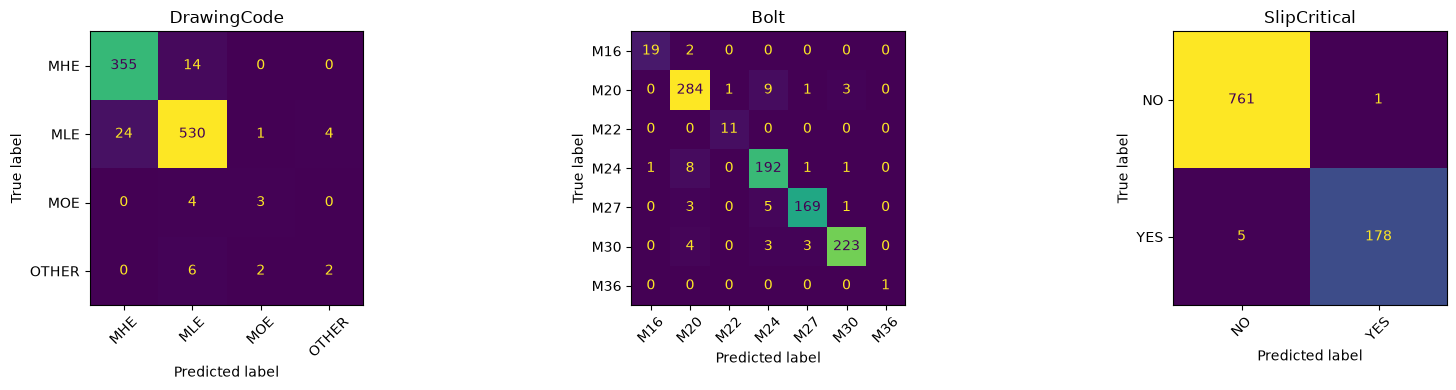

In [ ]:
fig,axes=plt.subplots(1,3,figsize=(17,4))
for ax,c in zip(axes,['DrawingCode','Bolt','SlipCritical']):
    labs=sorted(set(test_df[c].astype(str))|set(pred_df[c].astype(str)))
    ConfusionMatrixDisplay.from_predictions(test_df[c].astype(str),pred_df[c].astype(str),labels=labs,ax=ax,colorbar=False);ax.set_title(c);ax.tick_params(axis='x',rotation=45)
plt.tight_layout();plt.show()

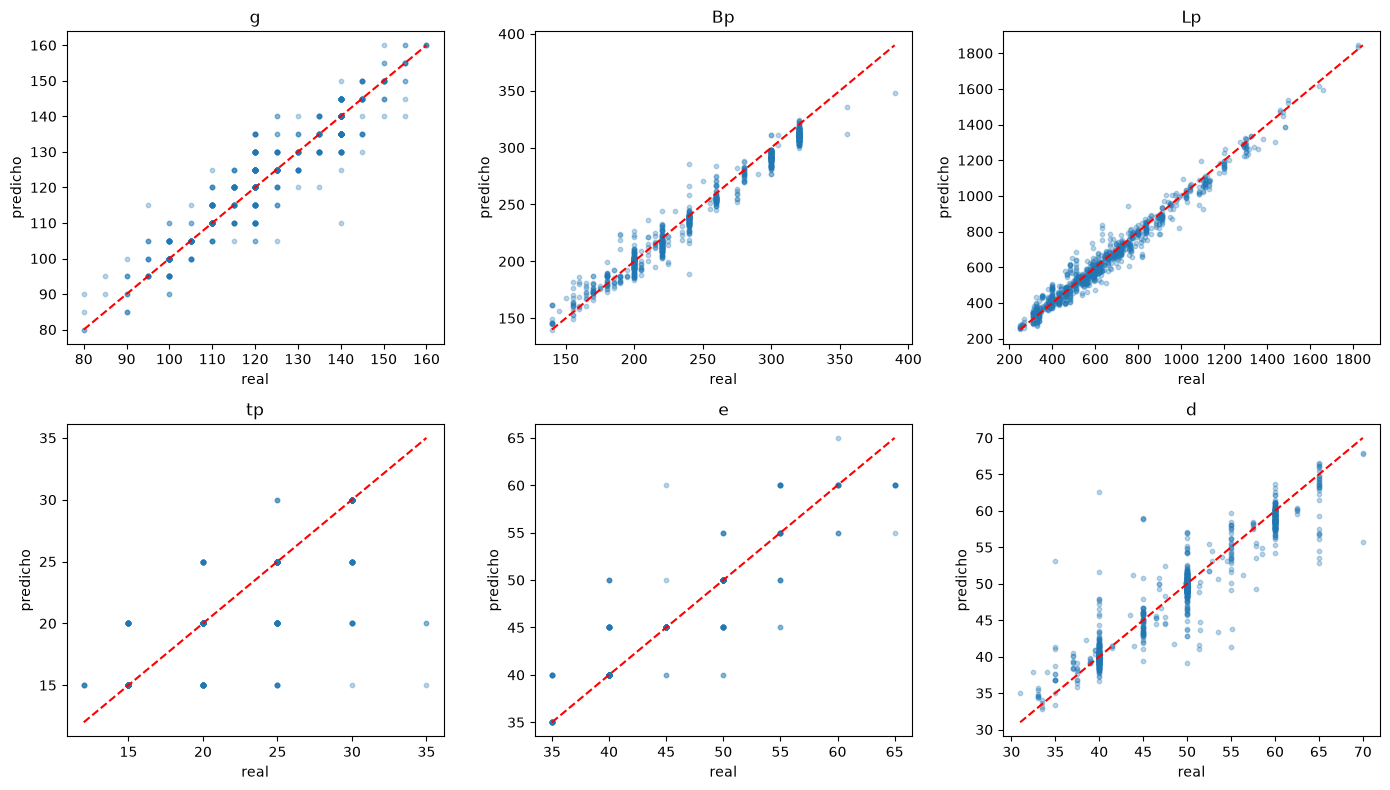

In [ ]:
fig,axes=plt.subplots(2,3,figsize=(14,8))
for ax,c in zip(axes.flat,REGRESSION_ALWAYS):
    r=test_df[c].to_numpy();p=pred_df[c].to_numpy();ax.scatter(r,p,s=10,alpha=.3);lo=min(r.min(),p.min());hi=max(r.max(),p.max());ax.plot([lo,hi],[lo,hi],'r--');ax.set(title=c,xlabel='real',ylabel='predicho')
plt.tight_layout();plt.show()

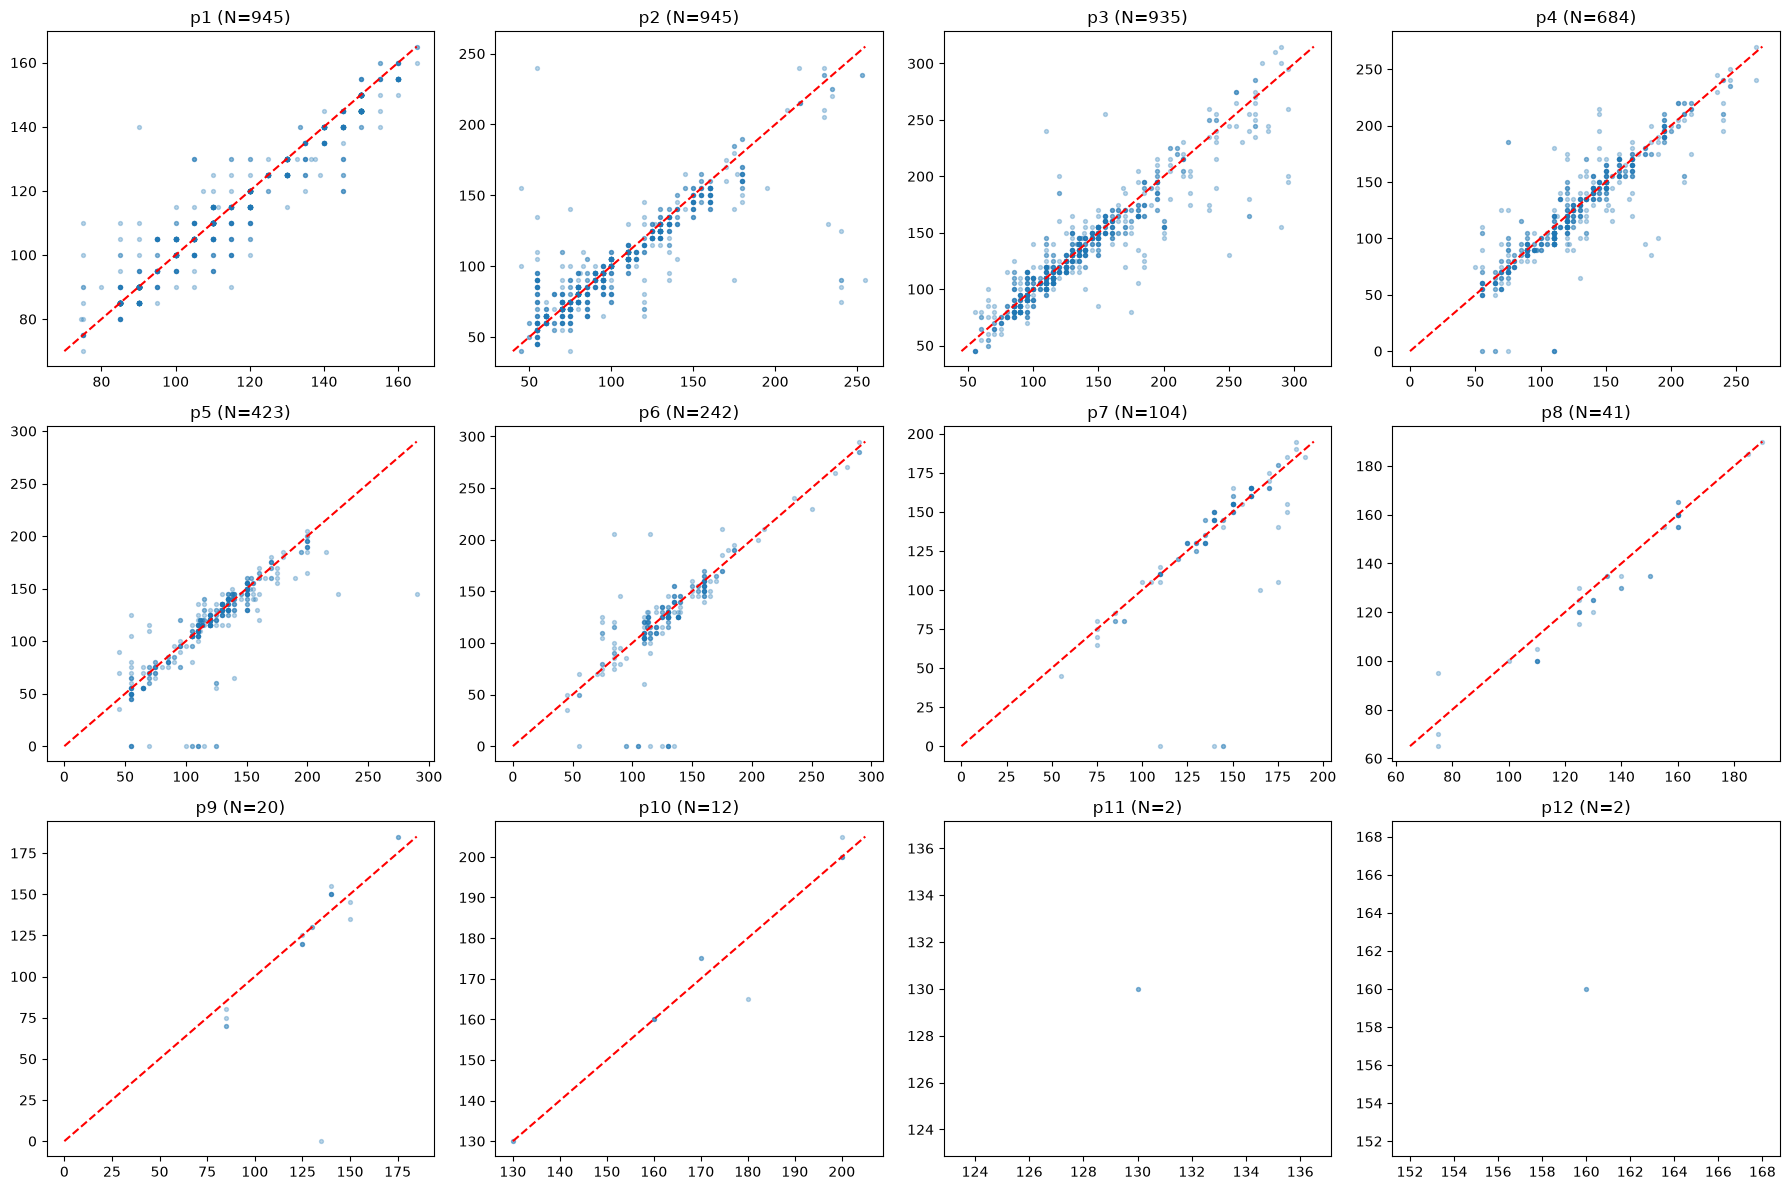

In [ ]:
fig,axes=plt.subplots(3,4,figsize=(18,12))
for ax,c in zip(axes.flat,P_COLUMNS):
    m=test_df[c].fillna(0).to_numpy()>0;r=test_df.loc[m,c].to_numpy();p=pred_df.loc[m,c].to_numpy()
    if not m.any():ax.axis('off');continue
    ax.scatter(r,p,s=8,alpha=.3);lo=min(r.min(),p.min());hi=max(r.max(),p.max());ax.plot([lo,hi],[lo,hi],'r--');ax.set_title(f'{c} (N={m.sum()})')
plt.tight_layout();plt.show()

## 8. Inspección de casos y errores

In [ ]:
def compare_row(i):
    cols=['DrawingCode','Bolt','SlipCritical']+REGRESSION_ALWAYS
    table=pd.DataFrame({'real':test_df.loc[i,cols].astype(object),'predicho':pred_df.loc[i,cols].astype(object)})
    ptab=pd.DataFrame({'p_real':test_df.loc[i,P_COLUMNS].values,'label_real':test_df.loc[i,P_LABEL_COLUMNS].values,'p_pred':pred_df.loc[i,P_COLUMNS].values,'label_pred':pred_df.loc[i,P_LABEL_COLUMNS].values},index=P_COLUMNS)
    display(table);display(ptab)
compare_row(0)

,real,predicho
DrawingCode,MHE,MHE
Bolt,M27,M27
SlipCritical,NO,NO
g,140,140.0
Bp,320,312.0
Lp,910,873.422302
tp,25,25.0
e,50,50.0
d,50.0,49.670204


,p_real,label_real,p_pred,label_pred
p1,130.0,BEAM_TOP_FLANGE,130.0,BEAM_TOP_FLANGE
p2,115.0,BEAM_WEB_EXTREME,110.0,BEAM_WEB_EXTREME
p3,115.0,BEAM_WEB_EXTREME,110.0,BEAM_WEB_EXTREME
p4,195.0,BEAM_BOTTOM_FLANGE,190.0,BEAM_BOTTOM_FLANGE
p5,120.0,HAUNCH_WEB_CENTRAL,115.0,HAUNCH_WEB_CENTRAL
p6,130.0,HAUNCH_FLANGE,130.0,HAUNCH_FLANGE
p7,0.0,UNUSED,0.0,UNUSED
p8,0.0,UNUSED,0.0,UNUSED
p9,0.0,UNUSED,0.0,UNUSED
p10,0.0,UNUSED,0.0,UNUSED


In [ ]:
# Peores casos por suma de error de p activa + penalización por etiquetas distintas
real_p=test_df[P_COLUMNS].fillna(0).to_numpy(float); pred_p=pred_df[P_COLUMNS].to_numpy(float)
label_bad=(test_df[P_LABEL_COLUMNS].astype(str).to_numpy()!=pred_df[P_LABEL_COLUMNS].astype(str).to_numpy()).sum(1)
score=np.abs(real_p-pred_p).sum(1)+50*label_bad
worst=np.argsort(score)[::-1][:10]
display(pd.DataFrame({'indice_test':worst,'score':score[worst],'labels_incorrectas':label_bad[worst]}))
compare_row(int(worst[0]))

,indice_test,score,labels_incorrectas
0,173,905.0,5
1,784,870.0,6
2,484,860.0,5
3,143,645.0,5
4,60,635.0,5
5,557,635.0,5
6,547,630.0,5
7,630,625.0,2
8,748,595.0,5
9,194,595.0,5


,real,predicho
DrawingCode,MLE,MLE
Bolt,M30,M30
SlipCritical,NO,NO
g,145,145.0
Bp,300,284.0
Lp,1380,1316.797363
tp,20,20.0
e,50,50.0
d,55.0,57.633011


,p_real,label_real,p_pred,label_pred
p1,135.0,BEAM_TOP_FLANGE,135.0,BEAM_TOP_FLANGE
p2,135.0,BEAM_WEB_EXTREME,95.0,BEAM_WEB_EXTREME
p3,295.0,BEAM_WEB_EXTREME,195.0,BEAM_WEB_CENTRAL
p4,135.0,BEAM_BOTTOM_FLANGE,170.0,BEAM_WEB_EXTREME
p5,290.0,HAUNCH_WEB_EXTREME,145.0,BEAM_BOTTOM_FLANGE
p6,115.0,HAUNCH_WEB_EXTREME,205.0,HAUNCH_WEB_EXTREME
p7,175.0,HAUNCH_FLANGE,105.0,HAUNCH_WEB_EXTREME
p8,0.0,UNUSED,175.0,HAUNCH_FLANGE
p9,0.0,UNUSED,0.0,UNUSED
p10,0.0,UNUSED,0.0,UNUSED


## 9. Guardado del bundle

In [ ]:
OUTPUT_DIR=MODEL_DIR/'artifacts';OUTPUT_DIR.mkdir(exist_ok=True)
torch.save(model.state_dict(),OUTPUT_DIR/'model.pt')
with open(OUTPUT_DIR/'preprocessor.pkl','wb') as f:pickle.dump(pre,f)
metadata={'version':'V3-p-labels','epochs':EPOCHS,'learning_rate':LEARNING_RATE,'best_epoch':history['best_epoch'],'n_train':len(train_df),'n_val':len(val_df),'n_test':len(test_df),'classification':cls_metrics,'structure':structure_metrics,'features':CATEGORICAL_FEATURES+NUMERIC_FEATURES}
(OUTPUT_DIR/'metadata.json').write_text(json.dumps(metadata,indent=2,default=float),encoding='utf-8')
print('Guardado en',OUTPUT_DIR.resolve())

Guardado en C:\Users\aarbona\OneDrive - Tecnicas Reunidas, S.A\Documentos\proyecto_uniones\V3\model\data\artifacts


## 10. Inferencia sobre filas nuevas
Las filas nuevas deben contener las columnas de entrada de `CATEGORICAL_FEATURES + NUMERIC_FEATURES`; no necesitan objetivos.

In [ ]:
@torch.no_grad()
def predict_dataframe(input_df):
    xcat,xnum=pre.transform_features(input_df)
    model.eval()
    raw=model(torch.as_tensor(xcat).to(device),torch.as_tensor(xnum,dtype=torch.float32).to(device))
    raw={k:v.cpu().numpy() for k,v in raw.items()}
    return decode(raw,pre)

df_test = pd.read_csv(MODEL_DIR / "test_input_25.csv")
example_prediction=predict_dataframe(df_test)
result = (pd.concat([df_test[['BEAM','COLUMN']].reset_index(drop=True),example_prediction],axis=1))

result.to_csv(MODEL_DIR / "test_results_v3_a.csv")

KeyError: "['BEAM_d_mm', 'BEAM_bf_mm', 'BEAM_tw_mm', 'BEAM_tf_mm', 'BEAM_r1_mm', 'BEAM_wely_mm', 'BEAM_w_kgm', 'COLUMN_d_mm', 'COLUMN_bf_mm', 'COLUMN_tw_mm', 'COLUMN_tf_mm', 'COLUMN_r1_mm', 'COLUMN_wely_mm', 'COLUMN_w_kgm', 'fy_acero_mpa', 'fu_acero_mpa', 'fy_tornillo_mpa', 'fu_tornillo_mpa', 'fv_tornillo_mpa'] not in index"